In [1]:
import pandas as pd
data={
    'Name':["A","B","C","D","E"],
    'Hours Studied':[2,5,1,7,4],
    'Attendance':[75,90,60,95,85],
    'Previous Score':[60,72,50,80,65],
    'Final Score':[62,78,48,88,70]
}
df=pd.DataFrame(data)
df


,Name,Hours Studied,Attendance,Previous Score,Final Score
0,A,2,75,60,62
1,B,5,90,72,78
2,C,1,60,50,48
3,D,7,95,80,88
4,E,4,85,65,70


In [2]:
average_marks=df["Final Score"].mean()
max_marks=df["Final Score"].max()
df[df['Final Score']== max_marks]["Name"]

3    D
Name: Name, dtype: str

In [3]:
df.info

<bound method DataFrame.info of   Name  Hours Studied  Attendance  Previous Score  Final Score
0    A              2          75              60           62
1    B              5          90              72           78
2    C              1          60              50           48
3    D              7          95              80           88
4    E              4          85              65           70>

In [4]:
df.describe()

,Hours Studied,Attendance,Previous Score,Final Score
count,5.000000,5.000000,5.000000,5.000000
mean,3.800000,81.000000,65.400000,69.200000
std,2.387467,13.874437,11.436783,15.270887
min,1.000000,60.000000,50.000000,48.000000
25%,2.000000,75.000000,60.000000,62.000000
50%,4.000000,85.000000,65.000000,70.000000
75%,5.000000,90.000000,72.000000,78.000000
max,7.000000,95.000000,80.000000,88.000000


Text(0.5, 1.0, 'Hours Studied vs Final Score')

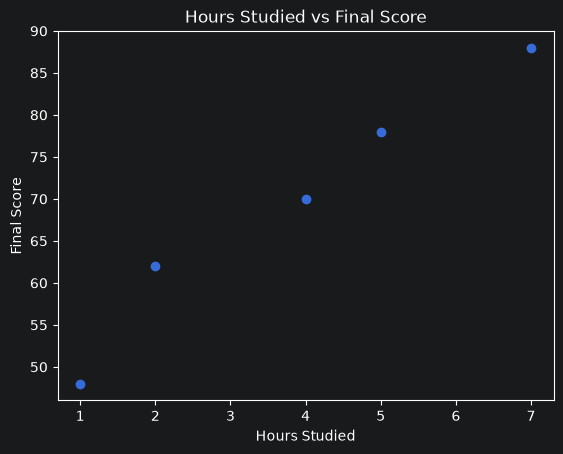

In [5]:
import matplotlib.pyplot as mat
mat.scatter(df["Hours Studied"],df["Final Score"])
mat.xlabel("Hours Studied")
mat.ylabel("Final Score")
mat.title("Hours Studied vs Final Score")

In [6]:
correlation=df["Hours Studied"].corr(df["Final Score"])
print(correlation)

0.9819318018553677


In [7]:
correlation1=df["Attendance"].corr(df["Final Score"])
print(correlation1)

0.9840709677206173


In [8]:
correlation2=df[("Previous Score")].corr(df["Final Score"])
print(correlation2)

0.9985695887399726


In [9]:
X=df[["Hours Studied","Attendance","Previous Score"]]
Y=df["Final Score"]

In [10]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(X,Y,test_size=0.2,random_state=42)
print(x_test.shape)
print(x_train.shape)

(1, 3)
(4, 3)


In [11]:
from sklearn.linear_model import LinearRegression
model=LinearRegression()
model.fit(x_train,y_train)
y_pred=model.predict(x_test)
print(y_pred)

[78.4]


In [12]:
print("Actual Score",y_test.values)

Actual Score [78]


In [13]:
from sklearn.metrics import mean_absolute_error
mae=mean_absolute_error(y_test,y_pred)
print(mae)

0.3999999999999915


In [14]:
import numpy as np
np.random.seed(42)
n=30
hours=np.random.randint(1,9,n)
attendance=np.random.randint(50,101,n)
previous=np.random.randint(40,91,n)
final=(0.5*previous+2*hours+0.2*attendance+np.random.normal(0,4.5,n))
final=np.clip(final,0,100).round().astype(int)
data={
    "Name":[f"student_{i+1}" for i in range(n)],
    "Hours Studied":hours,
    "Attendance":attendance,
    "Previous Score":previous,
    "Final Score":final
}
df=pd.DataFrame(data)
print(df)
print(df.shape)

          Name  Hours Studied  Attendance  Previous Score  Final Score
0    student_1              7          70              59           61
1    student_2              4          82              67           70
2    student_3              5          61              86           66
3    student_4              7          71              46           59
4    student_5              3          93              83           68
5    student_6              8          74              47           55
6    student_7              5          98              86           66
7    student_8              5          76              74           65
8    student_9              7          91              53           55
9   student_10              2          77              56           45
10  student_11              3          65              75           56
11  student_12              7          64              89           70
12  student_13              3          96              79           58
13  st

In [15]:
print(np.random.normal(0,1,5))

[-0.93376284  0.78420819 -0.61487576  0.33289244 -1.38071702]


In [16]:
print(df.isnull().sum())

Name              0
Hours Studied     0
Attendance        0
Previous Score    0
Final Score       0
dtype: int64


In [17]:
x=df[["Hours Studied","Attendance","Previous Score"]]
y=df[["Final Score"]]

In [18]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=20)

In [19]:
print(x_train)

    Hours Studied  Attendance  Previous Score
18              8          56              68
27              2          58              87
24              4          74              75
23              8          53              49
21              5          88              83
5               8          74              47
25              6          63              53
19              3          70              57
14              8          93              41
17              8         100              43
6               5          98              86
16              4          86              81
8               7          91              53
0               7          70              59
2               5          61              86
7               5          76              74
22              2          67              73
11              7          64              89
20              6          58              65
9               2          77              56
28              8          75     

In [20]:
print(x_test)

    Hours Studied  Attendance  Previous Score
13              3         100              43
4               3          93              83
1               4          82              67
10              3          65              75
29              4          51              47
12              3          96              79


In [21]:
print(y_train)

    Final Score
18           64
27           62
24           66
23           48
21           74
5            55
25           57
19           50
14           59
17           58
6            66
16           69
8            55
0            61
2            66
7            65
22           53
11           70
20           55
9            45
28           49
15           46
26           60
3            59


In [22]:
print(y_test)

    Final Score
13           44
4            68
1            70
10           56
29           47
12           58


In [23]:
model1=LinearRegression()
model1.fit(x_train,y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 3)","[[1.67,0.13,0.46]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['Hours Studied','Attendance','Previous Score']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[10.38]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


In [24]:
print(model1)

LinearRegression()


In [25]:
y_pred=model1.predict(x_test)

In [26]:
print(y_pred)

[[47.9990944 ]
 [65.49996006]
 [58.3955659 ]
 [58.2264778 ]
 [45.21727032]
 [64.04506434]]


In [27]:
print(y_test)

    Final Score
13           44
4            68
1            70
10           56
29           47
12           58


In [28]:
mae=mean_absolute_error(y_test,y_pred)

In [29]:
print("Mean Absolute error is ",mae)

Mean Absolute error is  4.692973376929864


In [30]:
print("Coefficients:",model1.coef_)
print("Intercept:",model1.intercept_)

Coefficients: [[1.66709721 0.12834385 0.45998181]]
Intercept: [10.38419997]


In [31]:
from sklearn.metrics import r2_score
r2=r2_score(y_test,y_pred)
print("r2_score ",r2)

r2_score  0.6405634866902521


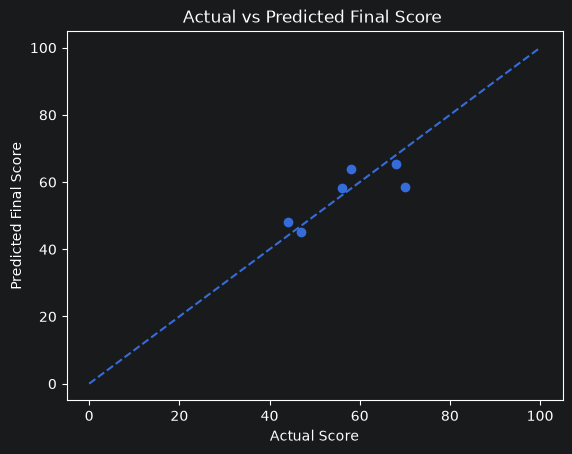

In [32]:
mat.scatter(y_test,y_pred)
mat.xlabel("Actual Score")
mat.ylabel("Predicted Final Score")
mat.title("Actual vs Predicted Final Score ")
mat.plot([0,100],[0,100],linestyle="--")
mat.show()

In [33]:
import joblib
joblib.dump(model,"student_performance_model.pkl")
print("Model Saved successfully")

Model Saved successfully
